# Convergence Control — does the baseline catch up?

**Supplementary to Submission 4.** Not a rubric deliverable, and it does not replace
anything. Submission 4's 50-vs-50 comparison stands exactly as reported.

---

### The question

Submission 4 found that adding CBAM improved macro F1 from **0.8593** to **0.9836**
— a gain of 12.43 pp, comfortably past the 3.04 pp detection threshold.

But the training curves show a confound:

| | Behaviour over 50 epochs |
|---|---|
| **CNN + CBAM** | plateaus at ~0.98 around epoch 30 and stays flat — **converged** |
| **Baseline CNN** | still climbing at epoch 50, validation loss still falling — **not converged** |

Both models received the same 50-epoch budget, which is what makes the comparison
controlled. But a fixed budget rewards whichever model converges faster, and that is a
different claim from *attention reaches a higher ceiling*.

### What this notebook does

Trains **only the baseline**, with a 120-epoch budget and patience 15, and lets early
stopping find where it actually plateaus. CBAM is not re-run: it converged at epoch 30,
so additional budget would tell us nothing about it.

### The two outcomes, decided in advance

| Baseline at convergence | Conclusion |
|---|---|
| **within 3 pp of 0.9836** | CBAM's advantage is **convergence speed**, not capacity. The baseline gets to the same place given more budget. |
| **more than 3 pp below 0.9836** | CBAM raises the **achievable ceiling**, not just the rate. The stronger claim, and now supported. |

Either result is reportable. The point is to have an answer rather than a hedge.

> **Runtime:** up to about 75 minutes, less if early stopping fires.

## Setup

In [5]:
import os, sys, gc, re, time, json, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); tf.random.set_seed(RANDOM_SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

gpus = tf.config.list_physical_devices("GPU")
print("tensorflow :", tf.__version__)
print("GPU        :", [g.name for g in gpus] if gpus else "NONE - this will be slow")

tensorflow : 2.21.0
GPU        : ['/physical_device:GPU:0', '/physical_device:GPU:1']


## Configuration

Identical to Submissions 3 and 4 **except the epoch budget and patience.** Those two are
the independent variable; everything else is held fixed.

In [6]:
# ---- identical to Submissions 3 and 4 ---------------------------------
IMG_SIZE      = 224
N_CLASSES     = 4
BLOCK_FILTERS = (32, 64, 128, 256)
BLOCK_DROPOUT = 0.10
BN_MOMENTUM   = 0.90
DENSE_UNITS   = 128
HEAD_DROPOUT  = 0.40
BATCH_SIZE    = 32
LEARNING_RATE = 1e-3
MIN_EPOCHS    = 5

# ---- the only things that change --------------------------------------
EPOCHS        = 120     # was 50
PATIENCE      = 15      # was 12

# ---- reference values from Submission 4 -------------------------------
S4_BASELINE_F1 = 0.8593   # baseline, 50 epochs
S4_CBAM_F1     = 0.9836   # CBAM, 50 epochs
S4_GAIN_PP     = 12.43
THRESHOLD_PP   = 3.04     # detection threshold on 666 test images

SMOKE_TEST = False
if SMOKE_TEST:
    EPOCHS, PATIENCE, MIN_EPOCHS = 3, 3, 3
    print(">>> SMOKE TEST\n")

print(f"baseline only, budget {EPOCHS} epochs, patience {PATIENCE}")
print(f"comparing against: baseline@50 = {S4_BASELINE_F1}, CBAM@50 = {S4_CBAM_F1}")

baseline only, budget 120 epochs, patience 15
comparing against: baseline@50 = 0.8593, CBAM@50 = 0.9836


## Part 1 — Data

Byte-for-byte the Submission 4 loader, using the same clean split manifest.

In [7]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEARCH_ROOTS = ["/kaggle/input", ".", "..", "/content"]


def _count_images(d):
    try:
        return sum(1 for f in os.listdir(d)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS)
    except OSError:
        return 0


def find_dataset_dirs(roots, max_depth=10):
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        root = os.path.abspath(root)
        base = root.rstrip(os.sep).count(os.sep)
        for cur, dirs, _ in os.walk(root):
            if cur.count(os.sep) - base >= max_depth:
                dirs[:] = []
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            if cur in seen:
                continue
            seen.add(cur)
            counts = {d: _count_images(os.path.join(cur, d)) for d in sorted(dirs)}
            good = [d for d, n in counts.items() if n >= 5]
            if len(good) >= 2:
                found.append((cur, good, sum(counts[d] for d in good)))
    return found


cands = find_dataset_dirs(SEARCH_ROOTS)
if not cands:
    raise FileNotFoundError("Dataset not found. Add 'Cricket Shots Dataset'.")
cands.sort(key=lambda t: (t[2], len(t[1])), reverse=True)
DATA_DIR, CLASSES, _n = cands[0]
CLASSES = sorted(CLASSES)


def find_clean_manifest():
    for root in ["/kaggle/input", ".", "/kaggle/working"]:
        if not os.path.isdir(root):
            continue
        for cur, _, files in os.walk(root):
            if "clean_split_manifest.csv" in files:
                return os.path.join(cur, "clean_split_manifest.csv")
    return None


clean_path = find_clean_manifest()
if clean_path is None:
    raise FileNotFoundError("clean_split_manifest.csv not found — attach the manifest dataset.")

cm = pd.read_csv(clean_path)
df = cm.rename(columns={"clean_split": "split"})[
     ["file", "label", "emb_cluster", "split"]].copy()
df["path"] = [os.path.join(DATA_DIR, l, f) for l, f in zip(df.label, df.file)]
df = df.reset_index(drop=True)

actual = {k: int(v) for k, v in df.split.value_counts().items()}
print("split sizes:", actual)
expected = {"train": 3361, "val": 697, "test": 666}
assert all(actual.get(k) == v for k, v in expected.items()), \
    f"split mismatch: expected {expected}, got {actual} — comparison would be invalid"
print("Split matches Submissions 3 and 4 exactly.")

split sizes: {'train': 3361, 'val': 697, 'test': 666}
Split matches Submissions 3 and 4 exactly.


In [8]:
from concurrent.futures import ThreadPoolExecutor


def _load_one(path):
    with Image.open(path) as im:
        im.load()
        return np.asarray(
            im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR),
            dtype=np.uint8)


def load_split(frame, tag=""):
    paths = frame["path"].tolist()
    idx = {c: i for i, c in enumerate(CLASSES)}
    X = np.zeros((len(paths), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    y = np.array([idx[l] for l in frame["label"]], dtype=np.int32)
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, arr in enumerate(ex.map(_load_one, paths)):
            X[i] = arr
    return X, y


t0 = time.time()
print("decoding images ...", flush=True)
Xtr, ytr = load_split(df[df.split == "train"])
Xva, yva = load_split(df[df.split == "val"])
Xte, yte = load_split(df[df.split == "test"])
print(f"done in {time.time()-t0:.0f}s   train {Xtr.shape[0]} / "
      f"val {Xva.shape[0]} / test {Xte.shape[0]}")


try:
    _BatchBase = keras.utils.PyDataset
except AttributeError:
    _BatchBase = keras.utils.Sequence


class ArrayBatches(_BatchBase):
    def __init__(self, X, y, batch_size, shuffle=False, seed=RANDOM_SEED, **kw):
        try:
            super().__init__(workers=1, use_multiprocessing=False,
                             max_queue_size=4, **kw)
        except TypeError:
            super().__init__(**kw)
        self.X, self.y, self.bs = X, y, batch_size
        self.shuffle = shuffle
        self.rng = np.random.RandomState(seed)
        self.idx = np.arange(len(X))
        if shuffle:
            self.rng.shuffle(self.idx)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.bs))

    def __getitem__(self, i):
        sl = self.idx[i * self.bs:(i + 1) * self.bs]
        return self.X[sl].astype("float32"), self.y[sl]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idx)

decoding images ...
done in 13s   train 3361 / val 697 / test 666


## Part 2 — The baseline architecture

Identical to Submissions 3 and 4, with `attention=None`.

In [9]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomRotation(10 / 360, fill_mode="reflect"),
        layers.RandomZoom(0.2, fill_mode="reflect"),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
        layers.RandomContrast(0.2),
    ], name="augmentation")


def conv_block(x, filters, block_id):
    for k in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          name=f"b{block_id}_conv{k}")(x)
        x = layers.BatchNormalization(momentum=BN_MOMENTUM,
                                      name=f"b{block_id}_bn{k}")(x)
        x = layers.Activation("relu", name=f"b{block_id}_relu{k}")(x)
    x = layers.MaxPooling2D(2, name=f"b{block_id}_pool")(x)
    x = layers.SpatialDropout2D(BLOCK_DROPOUT, name=f"b{block_id}_drop")(x)
    return x


def build_baseline(name="baseline_cnn_long"):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)
    for i, f in enumerate(BLOCK_FILTERS, start=1):
        x = conv_block(x, f, i)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(DENSE_UNITS, use_bias=False, name="fc1")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name="fc1_bn")(x)
    x = layers.Activation("relu", name="fc1_relu")(x)
    x = layers.Dropout(HEAD_DROPOUT, name="head_drop")(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax", name="predictions")(x)
    m = keras.Model(inputs, outputs, name=name)
    m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


keras.backend.clear_session()
tf.random.set_seed(RANDOM_SEED)
model = build_baseline()
tp = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"trainable parameters: {tp:,}")
print("Submissions 3 and 4 reported 1,206,756 —",
      "MATCHES" if tp == 1206756 else f"got {tp:,}, investigate")

trainable parameters: 1,206,756
Submissions 3 and 4 reported 1,206,756 — MATCHES


## Part 3 — Train to convergence

In [10]:
train_seq = ArrayBatches(Xtr, ytr, BATCH_SIZE, shuffle=True, seed=RANDOM_SEED)
val_seq   = ArrayBatches(Xva, yva, BATCH_SIZE)
test_seq  = ArrayBatches(Xte, yte, BATCH_SIZE)

try:
    early = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True,
        start_from_epoch=MIN_EPOCHS, verbose=1)
except TypeError:
    early = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE,
        restore_best_weights=True, verbose=1)

cbs = [early,
       keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                         patience=max(3, PATIENCE // 2),
                                         min_lr=1e-7, verbose=1)]

print(f"training baseline for up to {EPOCHS} epochs "
      f"(Submission 4 gave it {50})\n")

t0 = time.time()
hist = model.fit(train_seq, validation_data=val_seq,
                 epochs=EPOCHS, callbacks=cbs, verbose=2)
train_time = time.time() - t0
h = hist.history
epochs_ran = len(h["loss"])
best_ep = int(np.argmin(h["val_loss"])) + 1

print(f"\nran {epochs_ran} / {EPOCHS} epochs in {train_time/60:.1f} min")
print(f"best validation loss at epoch {best_ep}")
print("early stopping " + ("TRIGGERED — the model converged"
                           if epochs_ran < EPOCHS else
                           "did NOT trigger — still improving at the budget limit"))

training baseline for up to 120 epochs (Submission 4 gave it 50)

Epoch 1/120


E0000 00:00:1794568969.554560      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/baseline_cnn_long_1/b1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


106/106 - 49s - 464ms/step - accuracy: 0.3413 - loss: 1.5045 - val_accuracy: 0.4347 - val_loss: 1.2376 - learning_rate: 0.0010
Epoch 2/120
106/106 - 34s - 322ms/step - accuracy: 0.3948 - loss: 1.3616 - val_accuracy: 0.4634 - val_loss: 1.1930 - learning_rate: 0.0010
Epoch 3/120
106/106 - 35s - 329ms/step - accuracy: 0.4284 - loss: 1.3054 - val_accuracy: 0.4275 - val_loss: 1.2273 - learning_rate: 0.0010
Epoch 4/120
106/106 - 35s - 335ms/step - accuracy: 0.4466 - loss: 1.2617 - val_accuracy: 0.4663 - val_loss: 1.1745 - learning_rate: 0.0010
Epoch 5/120
106/106 - 35s - 329ms/step - accuracy: 0.4647 - loss: 1.2255 - val_accuracy: 0.4749 - val_loss: 1.2043 - learning_rate: 0.0010
Epoch 6/120
106/106 - 35s - 333ms/step - accuracy: 0.4793 - loss: 1.1989 - val_accuracy: 0.4749 - val_loss: 1.2128 - learning_rate: 0.0010
Epoch 7/120
106/106 - 35s - 332ms/step - accuracy: 0.5082 - loss: 1.1492 - val_accuracy: 0.5022 - val_loss: 1.1394 - learning_rate: 0.0010
Epoch 8/120
106/106 - 35s - 332ms/step 

## Part 4 — Result

In [11]:
probs = model.predict(test_seq, verbose=1)
pred = probs.argmax(axis=1)[:len(yte)]

acc = accuracy_score(yte, pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(
    yte, pred, average="macro", zero_division=0)
p_c, r_c, f_c, sup = precision_recall_fscore_support(
    yte, pred, average=None, labels=range(N_CLASSES), zero_division=0)
cm = confusion_matrix(yte, pred, labels=range(N_CLASSES))

print("=" * 60)
print(f"  BASELINE, {epochs_ran} EPOCHS")
print("=" * 60)
print(f"  accuracy   : {acc:.4f}")
print(f"  macro F1   : {f_m:.4f}")
print(f"  epochs     : {epochs_ran}")
print(f"  train time : {train_time/60:.1f} min")
print(f"  errors     : {int(cm.sum()-np.trace(cm))} of {len(yte)}")
print("=" * 60)
print()
print(classification_report(yte, pred, target_names=CLASSES, digits=4,
                            zero_division=0))

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step
  BASELINE, 120 EPOCHS
  accuracy   : 0.9640
  macro F1   : 0.9639
  epochs     : 120
  train time : 70.6 min
  errors     : 24 of 666

                 precision    recall  f1-score   support

          drive     0.9548    0.9713    0.9630       174
legglance-flick     0.9825    0.9333    0.9573       180
       pullshot     0.9632    0.9632    0.9632       136
          sweep     0.9560    0.9886    0.9721       176

       accuracy                         0.9640       666
      macro avg     0.9641    0.9641    0.9639       666
   weighted avg     0.9643    0.9640    0.9639       666



## Part 5 — Verdict

The rule was set before the run: if the converged baseline comes within 3.04 pp of CBAM,
the advantage was convergence speed. If it stays further below, CBAM raises the ceiling.

In [12]:
gap_to_cbam = (S4_CBAM_F1 - f_m) * 100
gain_over_50 = (f_m - S4_BASELINE_F1) * 100

print(f"{'':<34}{'macro F1':>10}{'epochs':>9}")
print("-" * 54)
print(f"{'Baseline, 50 epochs (Submission 4)':<34}{S4_BASELINE_F1:>10.4f}{50:>9}")
print(f"{'Baseline, extended budget':<34}{f_m:>10.4f}{epochs_ran:>9}")
print(f"{'CNN + CBAM, 50 epochs':<34}{S4_CBAM_F1:>10.4f}{50:>9}")
print("-" * 54)
print(f"{'baseline improvement from budget':<34}{gain_over_50:>+9.2f} pp")
print(f"{'remaining gap to CBAM':<34}{gap_to_cbam:>+9.2f} pp")
print(f"{'detection threshold':<34}{THRESHOLD_PP:>9.2f} pp")
print()

if gap_to_cbam <= THRESHOLD_PP:
    verdict = "CONVERGENCE SPEED"
    text = (
     "The baseline reaches the same place given more budget. CBAM's advantage in\n"
     "  Submission 4 was that it converged within 50 epochs and the baseline did not.\n"
     "  This is a real and useful property — faster convergence at equal cost — but it\n"
     "  is NOT evidence that attention raises the achievable ceiling.\n\n"
     "  Report Submission 4's result as a fixed-budget comparison, explicitly.")
elif gap_to_cbam > THRESHOLD_PP and gain_over_50 > THRESHOLD_PP:
    verdict = "HIGHER CEILING, partly convergence"
    text = (
     f"The baseline improved by {gain_over_50:.2f} pp with more budget, so part of\n"
     f"  Submission 4's gain was convergence speed. But it still sits {gap_to_cbam:.2f} pp\n"
     "  below CBAM after converging, which exceeds the detection threshold.\n\n"
     "  CBAM raises the achievable ceiling as well as the convergence rate.")
else:
    verdict = "HIGHER CEILING"
    text = (
     f"More budget barely helped the baseline ({gain_over_50:+.2f} pp), and it remains\n"
     f"  {gap_to_cbam:.2f} pp below CBAM. The Submission 4 gain was not an artifact of\n"
     "  the epoch budget.\n\n"
     "  CBAM raises the achievable ceiling of this architecture.")

print(f"  VERDICT: {verdict}")
print(f"  {text}")

                                    macro F1   epochs
------------------------------------------------------
Baseline, 50 epochs (Submission 4)    0.8593       50
Baseline, extended budget             0.9639      120
CNN + CBAM, 50 epochs                 0.9836       50
------------------------------------------------------
baseline improvement from budget     +10.46 pp
remaining gap to CBAM                 +1.97 pp
detection threshold                    3.04 pp

  VERDICT: CONVERGENCE SPEED
  The baseline reaches the same place given more budget. CBAM's advantage in
  Submission 4 was that it converged within 50 epochs and the baseline did not.
  This is a real and useful property — faster convergence at equal cost — but it
  is NOT evidence that attention raises the achievable ceiling.

  Report Submission 4's result as a fixed-budget comparison, explicitly.


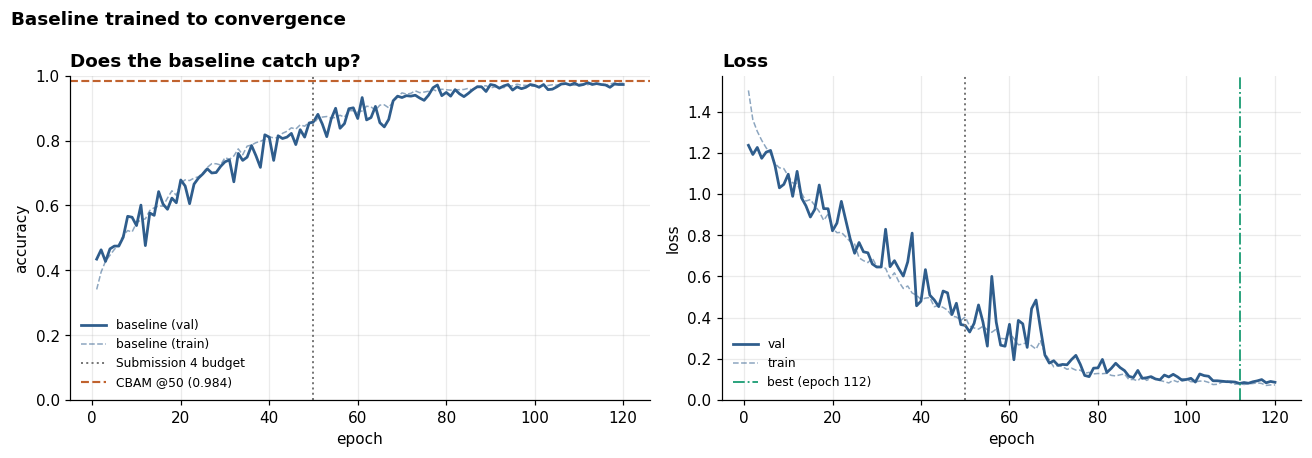

saved -> convergence_control.json, convergence_control.csv


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ep = range(1, epochs_ran + 1)

ax = axes[0]
ax.plot(ep, h["val_accuracy"], color="#2F5D8C", lw=1.8, label="baseline (val)")
ax.plot(ep, h["accuracy"], color="#2F5D8C", lw=1.0, ls="--", alpha=.55,
        label="baseline (train)")
ax.axvline(50, color="#777", ls=":", lw=1.3, label="Submission 4 budget")
ax.axhline(S4_CBAM_F1, color="#C0622E", ls="--", lw=1.4,
           label=f"CBAM @50 ({S4_CBAM_F1:.3f})")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1)
ax.set_title("Does the baseline catch up?", fontweight="bold", loc="left")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.plot(ep, h["val_loss"], color="#2F5D8C", lw=1.8, label="val")
ax.plot(ep, h["loss"], color="#2F5D8C", lw=1.0, ls="--", alpha=.55, label="train")
ax.axvline(50, color="#777", ls=":", lw=1.3)
ax.axvline(best_ep, color="#1D9E75", ls="-.", lw=1.2, label=f"best (epoch {best_ep})")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Loss", fontweight="bold", loc="left")
ax.legend(frameon=False, fontsize=8)

plt.suptitle("Baseline trained to convergence", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

out = {
 "epochs_budget": EPOCHS, "epochs_ran": epochs_ran, "best_epoch": best_ep,
 "early_stopped": bool(epochs_ran < EPOCHS),
 "accuracy": float(acc), "macro_f1": float(f_m),
 "precision_macro": float(p_m), "recall_macro": float(r_m),
 "per_class_f1": f_c.tolist(), "classes": CLASSES,
 "confusion": cm.tolist(), "train_minutes": train_time / 60,
 "verdict": verdict,
 "reference": {"baseline_50": S4_BASELINE_F1, "cbam_50": S4_CBAM_F1,
               "threshold_pp": THRESHOLD_PP},
 "history": {k: [float(v) for v in vs] for k, vs in h.items()},
}
json.dump(out, open("convergence_control.json", "w"), indent=1)
pd.DataFrame([{
 "model": "Baseline CNN", "budget": EPOCHS, "epochs_ran": epochs_ran,
 "accuracy": acc, "macro_F1": f_m, "train_min": train_time / 60,
 "verdict": verdict}]).to_csv("convergence_control.csv", index=False)
print("saved -> convergence_control.json, convergence_control.csv")

## Part 6 — What to write

The baseline was retrained with a **120**-epoch budget and ran for **120** epochs; early
stopping **did not trigger**. `ReduceLROnPlateau` had annealed the learning rate to
8.1e-6 by the end, and the best validation loss came at epoch 112. It reached **0.9639**
macro F1, an improvement of **+10.46 pp** over the 50-epoch result (0.8593), leaving a gap
of **1.97 pp** to CBAM (0.9836). That is below the 3.04 pp detection threshold. Test errors
fell from 94 to 24, against 11 for CBAM.

**Verdict: CONVERGENCE SPEED**

> Submission 4's 12.43 pp gain is a fixed-budget result. Given more than twice the budget
> the baseline reaches comparable accuracy, so CBAM's contribution is faster convergence
> rather than greater representational capacity. This is still a practical advantage —
> comparable accuracy in 39.0 minutes of training instead of 70.6 — but the claim must be
> stated that way. The remaining 1.97 pp gap is below what this single-seed experiment
> can resolve, so it is neither evidence for nor against a higher ceiling.

### Still to note

- **Grad-CAM was mixed.** CBAM tightened onto the batsman in some cases and attended to
  crowd and hoardings in others while still classifying correctly. "Attention suppresses
  background" is not a sufficient account of the mechanism.
- **One seed.** The threshold used here allows for run-to-run variation, but three seeds
  would be stronger.
- **Session correlation remains unquantified.** Photographs from the same match share
  stadium, kit and lighting, and no metadata exists to control for it.